# Laboratorium 2: trenowanie i strojenie klasyfikatora obrazów

Autor: Adam Pastuszak

Kod do sprawozdania, samo sprawozdanie jest w osobnym pliku PDF

## 1. Importy i ustawienia

In [1]:
import copy
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, TensorDataset

device = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = 30
STEP = 10
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.14.1+cu130 | urządzenie: cpu


## 2. Dane: FashionMNIST i stały podział 50 000 / 10 000 / 10 000

In [2]:
MEAN, STD = 0.2860, 0.3530
PAD_VALUE = -MEAN / STD


def to_tensors(ds):
    x = ds.data.float().div(255).sub(MEAN).div(STD).unsqueeze(1)
    return x, ds.targets.clone()


train_raw = torchvision.datasets.FashionMNIST("./data", train=True,
                                              download=True)
test_raw = torchvision.datasets.FashionMNIST("./data", train=False,
                                             download=True)
x_full, y_full = to_tensors(train_raw)
x_test, y_test = to_tensors(test_raw)

perm = torch.randperm(len(x_full), generator=torch.Generator().manual_seed(42))
train_idx, val_idx = perm[:50000], perm[50000:]
x_train, y_train = x_full[train_idx], y_full[train_idx]
x_val, y_val = x_full[val_idx], y_full[val_idx]

train_ds = TensorDataset(x_train, y_train)
train_eval_dl = DataLoader(train_ds, batch_size=1024)
val_dl = DataLoader(TensorDataset(x_val, y_val), batch_size=1024)
test_dl = DataLoader(TensorDataset(x_test, y_test), batch_size=1024)

print("Trening:", len(x_train), "| walidacja:", len(x_val),
      "| test:", len(x_test))

Trening: 50000 | walidacja: 10000 | test: 10000


## 3. Augmentacja na paczkach tensorów (odbicie i przesunięcie)

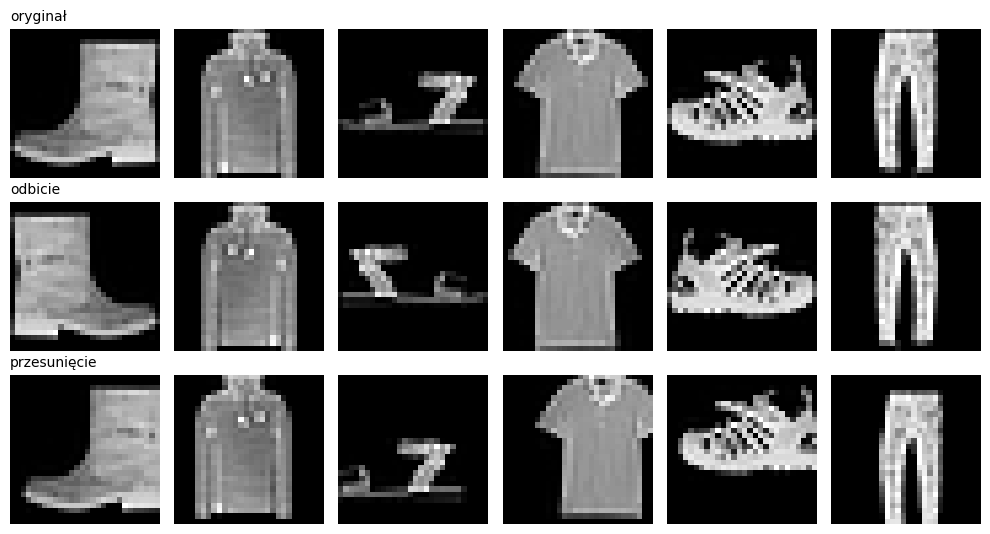

In [3]:
def augment(x, mode):
    if "flip" in mode:
        mask = torch.rand(x.size(0), device=x.device) < 0.5
        x = torch.where(mask[:, None, None, None], x.flip(-1), x)
    if "crop" in mode:
        b = x.size(0)
        xp = nn.functional.pad(x, (4, 4, 4, 4), value=PAD_VALUE)
        i = torch.randint(0, 9, (b,), device=x.device)
        j = torch.randint(0, 9, (b,), device=x.device)
        ar = torch.arange(28, device=x.device)
        rows = (i[:, None] + ar)[:, :, None]
        cols = (j[:, None] + ar)[:, None, :]
        idx = torch.arange(b, device=x.device)[:, None, None]
        x = xp[idx, 0, rows, cols].unsqueeze(1)
    return x


torch.manual_seed(1)
sample = x_train[:6]
views = [("oryginał", sample), ("odbicie", sample.flip(-1)),
         ("przesunięcie", augment(sample, "crop"))]
fig, axes = plt.subplots(3, 6, figsize=(10, 5.4))
for r, (title, imgs) in enumerate(views):
    for k in range(6):
        axes[r, k].imshow(imgs[k].squeeze() * STD + MEAN, cmap="gray")
        axes[r, k].axis("off")
    axes[r, 0].set_title(title, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 4. Model MLP z przełącznikami BatchNorm i dropout

In [4]:
class MLP(nn.Module):
    def __init__(self, in_dim=28 * 28, hidden=(256, 128), n_classes=10,
                 use_bn=False, p_drop=0.0):
        super().__init__()
        layers, d = [nn.Flatten()], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if use_bn:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            d = h
        layers.append(nn.Linear(d, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


print(MLP(use_bn=True, p_drop=0.3))

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=256, out_features=128, bias=True)
    (6): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 5. Funkcje treningu i oceny

fit po każdej epoce liczy czystą stratę treningową i walidacyjną w trybie eval() i na końcu przywraca checkpoint z najniższą stratą walidacyjną

In [5]:
def evaluate(model, dl):
    model.eval()
    crit = nn.CrossEntropyLoss(reduction="sum")
    loss_sum, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum / total, correct / total


BASE = {"aug": "brak", "bn": False, "dropout": 0.0, "wd": 0.0,
        "scheduler": False, "lr": 1e-3}


def fit(cfg, seed=0, epochs=EPOCHS):
    c = {**BASE, **cfg}
    torch.manual_seed(seed)
    model = MLP(use_bn=c["bn"], p_drop=c["dropout"]).to(device)
    loader = DataLoader(train_ds, batch_size=128, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    opt = torch.optim.Adam(model.parameters(), lr=c["lr"],
                           weight_decay=c["wd"])
    sched = None
    if c["scheduler"]:
        sched = torch.optim.lr_scheduler.StepLR(opt, step_size=STEP,
                                                gamma=0.5)
    crit = nn.CrossEntropyLoss()
    keys = ["train_loss", "train_eval_loss", "train_eval_acc",
            "val_loss", "val_acc"]
    hist = {k: [] for k in keys}
    best = {"epoch": 0, "val_loss": float("inf")}

    for epoch in range(1, epochs + 1):
        model.train()
        run = 0.0
        for xb, yb in loader:
            xb = augment(xb.to(device), c["aug"])
            yb = yb.to(device)
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()
            run += loss.item() * yb.numel()
        if sched:
            sched.step()
        tr_loss, tr_acc = evaluate(model, train_eval_dl)
        va_loss, va_acc = evaluate(model, val_dl)
        for k, v in zip(keys, [run / len(train_ds), tr_loss, tr_acc,
                               va_loss, va_acc]):
            hist[k].append(v)
        if va_loss < best["val_loss"]:
            best = {"epoch": epoch, "val_loss": va_loss, "val_acc": va_acc,
                    "train_eval_loss": tr_loss, "train_eval_acc": tr_acc,
                    "gap": va_loss - tr_loss,
                    "state": copy.deepcopy(model.state_dict())}

    model.load_state_dict(best["state"])
    return model, hist, best


def summary(name, best):
    return {"konfiguracja": name,
            "wybrana epoka": best["epoch"],
            "val loss": round(best["val_loss"], 4),
            "val acc [%]": round(best["val_acc"] * 100, 2),
            "train eval loss": round(best["train_eval_loss"], 4),
            "luka": round(best["gap"], 4)}


def plot_curves(ax_loss, ax_acc, hist, best, title):
    ep = range(1, len(hist["val_loss"]) + 1)
    ax_loss.plot(ep, hist["train_loss"], label="trening (train)")
    ax_loss.plot(ep, hist["train_eval_loss"], label="trening (eval)")
    ax_loss.plot(ep, hist["val_loss"], label="walidacja")
    ax_acc.plot(ep, [a * 100 for a in hist["train_eval_acc"]],
                label="trening (eval)")
    ax_acc.plot(ep, [a * 100 for a in hist["val_acc"]], label="walidacja")
    for ax in (ax_loss, ax_acc):
        ax.axvline(best["epoch"], color="gray", ls=":",
                   label="wybrana epoka")
        ax.set_xlabel("epoka")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    ax_loss.set(ylabel="strata", title=f"{title}: strata")
    ax_acc.set(ylabel="accuracy [%]", title=f"{title}: accuracy")

## 6. Baseline

Wybrana epoka: 9 | val loss 0.3012 | val acc 89.45% | czas 53 s


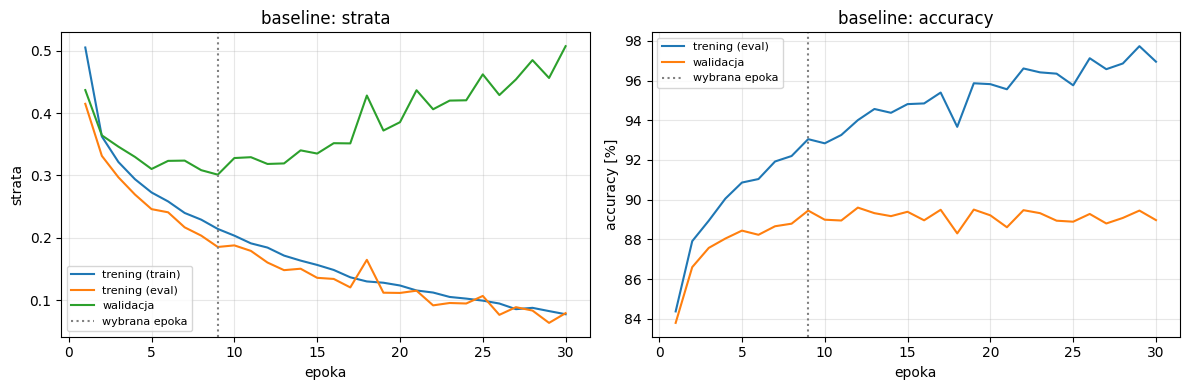

In [6]:
CONFIGS = {"baseline": {}}
results = {}
t0 = time.time()
results["baseline"] = fit(CONFIGS["baseline"])
_, hist, best = results["baseline"]
print(f"Wybrana epoka: {best['epoch']} | val loss {best['val_loss']:.4f}"
      f" | val acc {best['val_acc'] * 100:.2f}%"
      f" | czas {time.time() - t0:.0f} s")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
plot_curves(ax1, ax2, hist, best, "baseline")
plt.tight_layout()
plt.show()

## 7. Pojedyncze zmiany względem baseline

In [7]:
SINGLE = {
    "augmentacja: odbicie": {"aug": "flip"},
    "augmentacja: przesunięcie": {"aug": "crop"},
    "augmentacja: odbicie + przesunięcie": {"aug": "flip+crop"},
    "BatchNorm": {"bn": True},
    "dropout 0.2": {"dropout": 0.2},
    "dropout 0.3": {"dropout": 0.3},
    "dropout 0.5": {"dropout": 0.5},
    "weight decay 1e-4": {"wd": 1e-4},
    "weight decay 5e-4": {"wd": 5e-4},
    "scheduler StepLR": {"scheduler": True},
}
CONFIGS.update(SINGLE)
for name, cfg in SINGLE.items():
    t0 = time.time()
    results[name] = fit(cfg)
    print(f"{name:38s} {time.time() - t0:4.0f} s")

augmentacja: odbicie                     52 s


augmentacja: przesunięcie                63 s


augmentacja: odbicie + przesunięcie      66 s


BatchNorm                                55 s


dropout 0.2                              60 s


dropout 0.3                              59 s


dropout 0.5                              65 s


weight decay 1e-4                        58 s


weight decay 5e-4                        82 s


scheduler StepLR                         53 s


In [8]:
pd.DataFrame([summary(n, results[n][2]) for n in ["baseline", *SINGLE]])

,konfiguracja,wybrana epoka,val loss,val acc [%],train eval loss,luka
0,baseline,9,0.3012,89.45,0.1852,0.1160
1,augmentacja: odbicie,13,0.3111,88.98,0.2003,0.1108
2,augmentacja: przesunięcie,30,0.3728,86.22,0.3454,0.0274
3,augmentacja: odbicie + przesunięcie,28,0.3803,85.96,0.3539,0.0264
4,BatchNorm,4,0.3063,88.89,0.2304,0.0759
5,dropout 0.2,19,0.2977,90.02,0.1604,0.1372
6,dropout 0.3,19,0.2986,89.82,0.1784,0.1203
7,dropout 0.5,30,0.3035,89.11,0.2057,0.0979
8,weight decay 1e-4,9,0.3032,89.30,0.2024,0.1008
9,weight decay 5e-4,17,0.3114,89.04,0.1931,0.1183


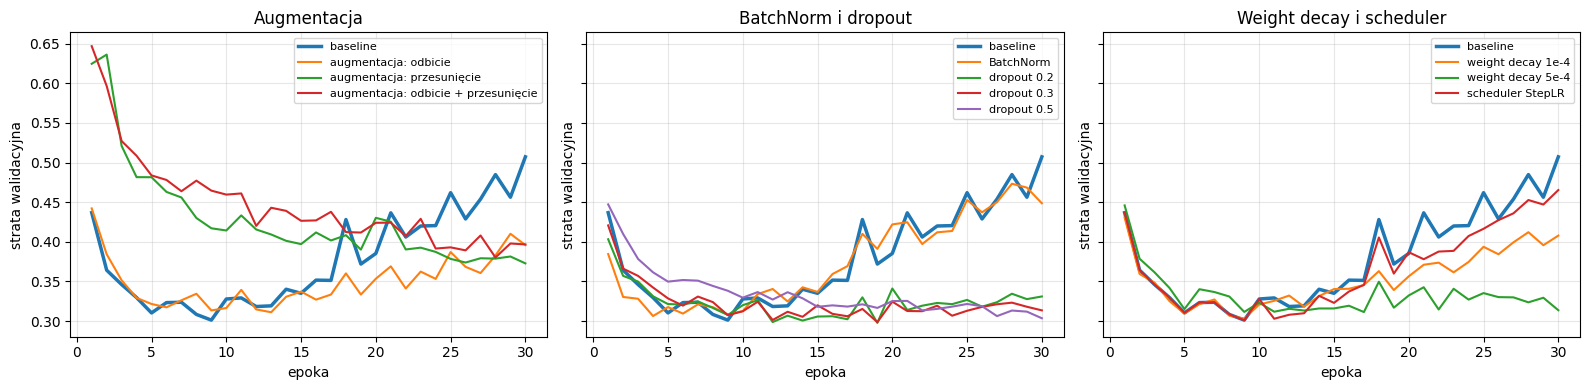

In [9]:
groups = [
    ("Augmentacja", ["augmentacja: odbicie", "augmentacja: przesunięcie",
                     "augmentacja: odbicie + przesunięcie"]),
    ("BatchNorm i dropout", ["BatchNorm", "dropout 0.2", "dropout 0.3",
                             "dropout 0.5"]),
    ("Weight decay i scheduler", ["weight decay 1e-4", "weight decay 5e-4",
                                  "scheduler StepLR"]),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (title, names) in zip(axes, groups):
    for n in ["baseline", *names]:
        h = results[n][1]["val_loss"]
        ax.plot(range(1, len(h) + 1), h, label=n,
                lw=2.5 if n == "baseline" else 1.5)
    ax.set(title=title, xlabel="epoka", ylabel="strata walidacyjna")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8. Kombinacje i wybór konfiguracji

In [10]:
COMBOS = {
    "dropout 0.3 + scheduler": {"dropout": 0.3, "scheduler": True},
    "dropout 0.3 + scheduler + wd 1e-4": {"dropout": 0.3,
                                          "scheduler": True, "wd": 1e-4},
    "dropout 0.3 + BatchNorm + scheduler": {"dropout": 0.3, "bn": True,
                                            "scheduler": True},
    "dropout 0.3 + BatchNorm + scheduler + wd 1e-4": {
        "dropout": 0.3, "bn": True, "scheduler": True, "wd": 1e-4},
    "wszystko z ćwiczenia (z augmentacją)": {
        "aug": "flip+crop", "bn": True, "dropout": 0.3, "wd": 1e-4,
        "scheduler": True},
}
CONFIGS.update(COMBOS)
for name, cfg in COMBOS.items():
    t0 = time.time()
    results[name] = fit(cfg)
    print(f"{name:48s} {time.time() - t0:4.0f} s")

best_name = min(results, key=lambda n: results[n][2]["val_loss"])
print("\nNajniższa strata walidacyjna:", best_name)

table = pd.DataFrame([summary(n, results[n][2]) for n in results])
table.sort_values("val loss").reset_index(drop=True)

dropout 0.3 + scheduler                            63 s


dropout 0.3 + scheduler + wd 1e-4                  61 s


dropout 0.3 + BatchNorm + scheduler                65 s


dropout 0.3 + BatchNorm + scheduler + wd 1e-4      67 s


wszystko z ćwiczenia (z augmentacją)               79 s

Najniższa strata walidacyjna: dropout 0.3 + BatchNorm + scheduler + wd 1e-4


,konfiguracja,wybrana epoka,val loss,val acc [%],train eval loss,luka
0,dropout 0.3 + BatchNorm + scheduler + wd 1e-4,19,0.2802,90.22,0.1462,0.1340
1,dropout 0.3 + BatchNorm + scheduler,19,0.2805,90.10,0.1387,0.1419
2,dropout 0.3 + scheduler + wd 1e-4,19,0.2846,89.83,0.1742,0.1105
3,dropout 0.3 + scheduler,12,0.2933,89.56,0.2035,0.0898
4,dropout 0.2,19,0.2977,90.02,0.1604,0.1372
5,dropout 0.3,19,0.2986,89.82,0.1784,0.1203
6,baseline,9,0.3012,89.45,0.1852,0.1160
7,scheduler StepLR,9,0.3012,89.45,0.1852,0.1160
8,weight decay 1e-4,9,0.3032,89.30,0.2024,0.1008
9,dropout 0.5,30,0.3035,89.11,0.2057,0.0979


## 9. Krzywe uczenia i luka generalizacji

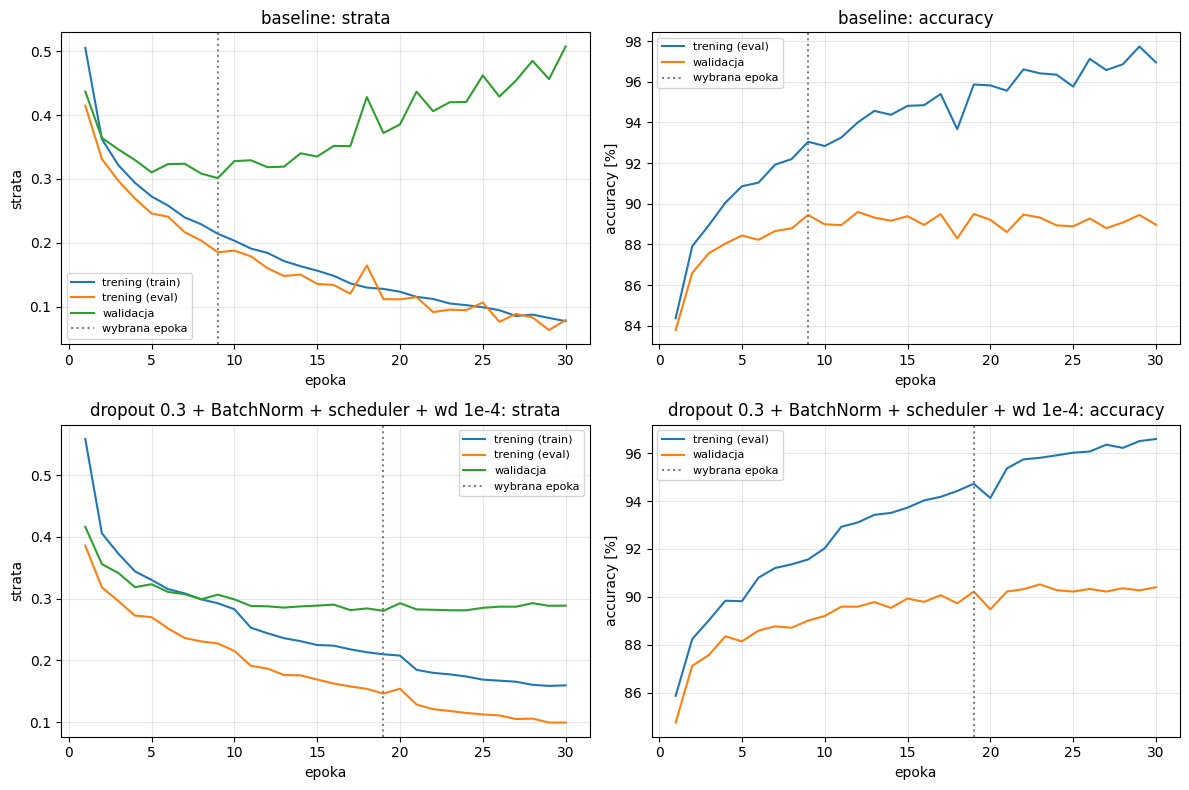

baseline: epoka 9 | train eval loss 0.1852 | val loss 0.3012 | luka 0.1160 | acc trening 93.05% | acc walid. 89.45%
  dla porównania epoka 30: train eval loss 0.0791 | val loss 0.5073 | luka 0.4282
dropout 0.3 + BatchNorm + scheduler + wd 1e-4: epoka 19 | train eval loss 0.1462 | val loss 0.2802 | luka 0.1340 | acc trening 94.72% | acc walid. 90.22%
  dla porównania epoka 30: train eval loss 0.0994 | val loss 0.2886 | luka 0.1892


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, name in zip(axes, ["baseline", best_name]):
    plot_curves(row[0], row[1], results[name][1], results[name][2], name)
plt.tight_layout()
plt.show()

for name in ["baseline", best_name]:
    b, h = results[name][2], results[name][1]
    print(f"{name}: epoka {b['epoch']} | train eval loss "
          f"{b['train_eval_loss']:.4f} | val loss {b['val_loss']:.4f} | "
          f"luka {b['gap']:.4f} | acc trening "
          f"{b['train_eval_acc'] * 100:.2f}% | acc walid. "
          f"{b['val_acc'] * 100:.2f}%")
    last_gap = h["val_loss"][-1] - h["train_eval_loss"][-1]
    print(f"  dla porównania epoka {len(h['val_loss'])}: train eval loss "
          f"{h['train_eval_loss'][-1]:.4f} | val loss "
          f"{h['val_loss'][-1]:.4f} | luka {last_gap:.4f}")

## 10. Powtórzenia z ziarnami 1 i 2

In [12]:
seed_runs = {n: [results[n]] for n in ["baseline", best_name]}
for name in seed_runs:
    for s in [1, 2]:
        seed_runs[name].append(fit(CONFIGS[name], seed=s))

rows = []
for name, runs in seed_runs.items():
    bs = [r[2] for r in runs]
    loss = [b["val_loss"] for b in bs]
    acc = [b["val_acc"] * 100 for b in bs]
    gap = [b["gap"] for b in bs]
    rows.append({"konfiguracja": name,
                 "wybrane epoki": " / ".join(str(b["epoch"]) for b in bs),
                 "val loss": f"{np.mean(loss):.4f} ± {np.std(loss):.4f}",
                 "val acc [%]": f"{np.mean(acc):.2f} ± {np.std(acc):.2f}",
                 "luka": f"{np.mean(gap):.4f} ± {np.std(gap):.4f}"})
pd.DataFrame(rows)

,konfiguracja,wybrane epoki,val loss,val acc [%],luka
0,baseline,9 / 9 / 7,0.3029 ± 0.0033,89.37 ± 0.09,0.1082 ± 0.0122
1,dropout 0.3 + BatchNorm + scheduler + wd 1e-4,19 / 21 / 21,0.2777 ± 0.0018,90.20 ± 0.03,0.1441 ± 0.0071


## 11. Accuracy testowa (liczona raz, po wyborze modelu)

In [13]:
for name in ["baseline", best_name]:
    test_loss, test_acc = evaluate(results[name][0], test_dl)
    accs = [evaluate(r[0], test_dl)[1] * 100 for r in seed_runs[name]]
    print(f"{name}: accuracy testowa {test_acc * 100:.2f}% "
          f"(strata {test_loss:.4f}) | średnio z 3 ziaren: "
          f"{np.mean(accs):.2f} ± {np.std(accs):.2f}%")

baseline: accuracy testowa 88.77% (strata 0.3337) | średnio z 3 ziaren: 88.53 ± 0.18%


dropout 0.3 + BatchNorm + scheduler + wd 1e-4: accuracy testowa 89.39% (strata 0.2996) | średnio z 3 ziaren: 89.53 ± 0.10%
